# CommitBench filtering — Python-only, explicitly typed commits

This notebook reads the CommitBench CSV files that you manually downloaded into `data/raw/`.
It does **not** download the dataset from Hugging Face.

## Expected input files
- `data/raw/train.csv`
- `data/raw/val.csv` (or `validation.csv`)
- `data/raw/test.csv`

## Outputs
- `data/processed/train.jsonl`
- `data/processed/validation.jsonl`
- `data/processed/test.jsonl`

Each JSONL record contains:
- `diff`: code diff, used as model input.
- `message`: cleaned original commit message, used as the generation target.
- `commit_type`: normalized explicit type label (`feat`, `fix`, `docs`, etc.), used later as the multi-task classification target.

Only Python-only rows whose messages start with a recognized explicit commit-type prefix are exported. Untyped messages are excluded; this notebook does not infer a type from the diff.

The output remains compatible with the current generation fine-tuning pipeline because it retains `diff` and `message`. The extra `commit_type` field is preserved for the later multi-task model.

Set `LIMIT_PER_SPLIT = 2000` for a small test run, or `None` to process every row. The limit counts input rows scanned per split.

In [1]:
# Install dependencies into the active notebook kernel if needed.
# This uses local CSVs; it does not download CommitBench itself.
#%pip install -q datasets tqdm matplotlib


In [2]:
import hashlib
import json
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
from datasets import load_dataset
from tqdm.auto import tqdm


c:\Users\ASUSD\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# ---------------------------------------------------------------------------
# Configuration — local Kiro / VS Code
# ---------------------------------------------------------------------------

# Preferred path from your project. If the notebook is moved, the relative
# fallback is checked as well.
PROJECT_DIR = Path(r"C:\Users\ASUSD\Desktop\Programing\seniorProject\OffHand")
CANDIDATE_RAW_DIRS = [PROJECT_DIR / "data" / "raw", Path.cwd() / "data" / "raw"]
RAW_DIR = next((p for p in CANDIDATE_RAW_DIRS if p.is_dir()), CANDIDATE_RAW_DIRS[0])

# Output paths are relative to the project folder when it exists.
OUTPUT_ROOT = PROJECT_DIR if PROJECT_DIR.is_dir() else Path.cwd()
OUT_DIR = OUTPUT_ROOT / "data" / "processed"
PLOT_DIR = OUT_DIR / "plots"

# Set to e.g. 2_000 for a quick test; use None for all input rows.
# This limit applies to rows SCANNED, not rows successfully kept.
LIMIT_PER_SPLIT = None

TARGET_LANGUAGE = "python"
# Do not cap only the training split: preserve its natural class distribution.
# Validation/test remain untouched for an honest evaluation.
MAX_PER_TYPE = {}
FIGURE_DPI = 140

print(f"Project/output root: {OUTPUT_ROOT.resolve()}")
print(f"Raw data directory:  {RAW_DIR.resolve()}")
print(f"Output directory:    {OUT_DIR.resolve()}")
print(f"Row limit per split: {LIMIT_PER_SPLIT}")


Project/output root: C:\Users\ASUSD\Desktop\Programing\seniorProject\OffHand
Raw data directory:  C:\Users\ASUSD\Desktop\Programing\seniorProject\OffHand\data\raw
Output directory:    C:\Users\ASUSD\Desktop\Programing\seniorProject\OffHand\data\processed
Row limit per split: None


In [4]:
# ---------------------------------------------------------------------------
# Filtering helpers (mirrors src/commit_model/diff_utils.py — kept inline so
# the notebook is self-contained and runs on Kaggle / Colab without the package)
# ---------------------------------------------------------------------------

CONVENTIONAL_PREFIX = re.compile(
    r"^(feat|fix|refactor|chore|docs|test|perf|style|build|ci)(\([\w./-]+\))?!?:\s+\S"
)

# Regex that matches the type prefix only (used for per-type counting)
TYPE_RE = re.compile(r"^(\w+)(\(.+?\))?!?:")

LOW_CONTENT_STOPLIST = {
    "fix", "wip", "update", "updates", "minor", "minor changes", "misc",
    "cleanup", "small fix", "typo", "changes", "stuff", "test", "tmp",
    "asdf", "oops", "fixup",
}

GENERATED_FILE_PATTERNS = [
    re.compile(p) for p in [
        r"package-lock\.json$", r"yarn\.lock$", r"pnpm-lock\.yaml$",
        r"Cargo\.lock$", r"Gemfile\.lock$", r"poetry\.lock$", r"uv\.lock$",
        r"\.min\.(js|css)$", r"\.map$", r"(?:^|/)dist/", r"(?:^|/)build/", r"(?:^|/)vendor/",
        r"\.svg$", r"\.snap$",
    ]
]

MAX_DIFF_CHARS = 4000
MAX_FILES_PER_DIFF = 6

# Placeholders injected by CommitBench into anonymised messages.
# Strip them from training data so the model never learns to generate them.
# (At inference time, postprocess.py also strips them — this is the training-side fix.)
_PLACEHOLDER_RE = re.compile(
    r"<(I|URL|EMAIL|HASH)>"
    r"|\(#<I>\)"
    r"|\b[0-9a-f]{7,40}\b"  # bare hex hashes that escaped the <HASH> anonymisation
    r"|https?://\S+"         # bare URLs that escaped the <URL> anonymisation
)


def is_generated_path(path: str) -> bool:
    return any(p.search(path) for p in GENERATED_FILE_PATTERNS)


def message_is_low_content(message: str) -> bool:
    first_line = message.strip().splitlines()[0] if message.strip() else ""
    has_prefix = CONVENTIONAL_PREFIX.match(first_line)
    subject = first_line.split(":", 1)[-1].strip() if has_prefix else first_line
    normalized = subject.lower().strip(" .!")
    return len(normalized) < 8 or normalized in LOW_CONTENT_STOPLIST


def split_diff_by_file(diff: str):
    """Split a unified diff into (path, hunk_text) chunks."""
    chunks = re.split(r"(?=^diff --git )", diff, flags=re.MULTILINE)
    files = []
    for chunk in chunks:
        if not chunk.strip():
            continue
        match = re.search(r"^diff --git a/(\S+) b/(\S+)", chunk)
        path = match.group(2) if match else "unknown"
        files.append((path, chunk))
    return files


def truncate_diff(diff: str):
    """Drop generated/lockfile paths, cap file count, and cap total length."""
    files = split_diff_by_file(diff)
    kept = [(p, c) for p, c in files if not is_generated_path(p)]
    if not kept:
        return None
    kept = kept[:MAX_FILES_PER_DIFF]
    pieces = []
    for path, chunk in kept:
        share = max(MAX_DIFF_CHARS // max(len(kept), 1), 200)
        pieces.append(chunk[:share])
    return "".join(pieces)[:MAX_DIFF_CHARS]


def clean_training_message(message: str) -> str:
    """Strip CommitBench placeholder tokens from a training message.

    Does NOT apply the lowercase-first-word cosmetic from postprocess.py —
    that is inference-time only and should not alter training labels.
    Returns an empty string if nothing meaningful remains after cleaning.
    """
    cleaned = _PLACEHOLDER_RE.sub("", message)
    # Collapse multiple spaces and trim
    cleaned = re.sub(r"[ \t]{2,}", " ", cleaned).strip()
    # Collapse dangling punctuation left behind: 'fix: (#)' -> 'fix:'
    cleaned = re.sub(r":\s*[()#\[\]]+\s*$", "", cleaned).strip()
    return cleaned


def extract_type(message: str):
    """Return the commit type prefix string, or None."""
    m = TYPE_RE.match(message.strip())
    return m.group(1) if m else None


# ---------------------------------------------------------------------------
# Programming-language filtering
# ---------------------------------------------------------------------------

_LANGUAGE_ALIASES = {
    "py": "python",
    "python": "python",
    "js": "javascript",
    "javascript": "javascript",
    "ts": "typescript",
    "typescript": "typescript",
    "java": "java",
    "go": "go",
    "php": "php",
    "rb": "ruby",
    "ruby": "ruby",
    "c++": "cpp",
    "cpp": "cpp",
    "py3": "python",
}


def _normalise_language(value: str) -> str:
    value = str(value).strip().lower()
    return _LANGUAGE_ALIASES.get(value, value)


def _languages_from_metadata(row: dict):
    """Return normalized language metadata, or None when no usable field exists."""
    for key in ("diff_languages", "languages", "language"):
        if key not in row or row[key] is None:
            continue
        value = row[key]
        if isinstance(value, (list, tuple, set)):
            raw_values = list(value)
        else:
            raw_values = re.split(r"[,;|]", str(value))
        languages = {
            _normalise_language(v)
            for v in raw_values
            if str(v).strip() and str(v).strip().lower() not in {"none", "nan", "unknown"}
        }
        if languages:
            return languages
    return None


def _languages_from_diff_paths(diff: str):
    """Infer languages from changed file extensions; unknown extensions are rejected."""
    paths = re.findall(
        r"^diff --git a/(.*?) b/(.*?)$",
        diff,
        flags=re.MULTILINE,
    )
    if not paths:
        return None

    extension_to_language = {".py": "python"}
    languages = set()
    for old_path, new_path in paths:
        path = new_path or old_path
        suffix = Path(path).suffix.lower()
        language = extension_to_language.get(suffix)
        if language is None:
            return {"__non_python_or_unknown__"}
        languages.add(language)
    return languages or None


def is_target_language_example(row: dict, target_language: str = TARGET_LANGUAGE) -> bool:
    """Keep only diffs whose changed-file paths confirm the target language.

    File extensions take priority because the requirement is Python-only changed
    files. Metadata is used only when paths cannot be parsed from the diff.
    """
    diff = row.get("diff") or ""
    languages_from_paths = _languages_from_diff_paths(diff)
    if languages_from_paths is not None:
        return languages_from_paths == {target_language}

    languages_from_metadata = _languages_from_metadata(row)
    return languages_from_metadata == {target_language}


In [5]:
# ---------------------------------------------------------------------------
# Load the manually downloaded local CommitBench CSV files
# ---------------------------------------------------------------------------

if not RAW_DIR.is_dir():
    raise FileNotFoundError(
        f"Raw data directory does not exist: {RAW_DIR}\n"
        "Create data/raw and put the downloaded CommitBench CSV files there."
    )

csv_files = sorted(RAW_DIR.glob("*.csv"))
if not csv_files:
    raise FileNotFoundError(
        f"No .csv files found in {RAW_DIR}. Found files: "
        f"{[p.name for p in RAW_DIR.iterdir()]}"
    )

print("CSV files found:")
for file in csv_files:
    print(f"  {file.name} ({file.stat().st_size / (1024**2):.1f} MiB)")

# Match common filename variants without requiring exact capitalization.
def find_split_file(aliases):
    for file in csv_files:
        stem = file.stem.lower().replace("-", "_").replace(" ", "_")
        if stem in aliases:
            return file
    for file in csv_files:
        stem = file.stem.lower().replace("-", "_").replace(" ", "_")
        if any(alias in stem for alias in aliases):
            return file
    return None

train_file = find_split_file({"train", "training", "train_set"})
val_file = find_split_file({"val", "valid", "validation", "dev", "val_set"})
test_file = find_split_file({"test", "testing", "test_set"})

if train_file is None:
    raise FileNotFoundError(
        "Could not identify the training CSV. Expected a filename like train.csv. "
        f"CSV files found: {[p.name for p in csv_files]}"
    )

# Map local files to canonical Hugging Face split names.
data_files = {"train": str(train_file)}
if val_file is not None:
    data_files["validation"] = str(val_file)
if test_file is not None:
    data_files["test"] = str(test_file)

print("\nLoading local CSV files with Hugging Face Datasets (no network download):")
for split_name, file_path in data_files.items():
    print(f"  {split_name}: {file_path}")

ds = load_dataset("csv", data_files=data_files)

# Normalize common column-name variants to the names expected by the filter.
for split_name in list(ds.keys()):
    columns = list(ds[split_name].column_names)
    lower_to_actual = {column.lower().strip(): column for column in columns}

    diff_candidates = ("diff", "patch", "code_diff", "diff_text", "changes")
    message_candidates = ("message", "commit_message", "commit_msg", "subject", "commitmessage")

    diff_col = next((lower_to_actual[name] for name in diff_candidates if name in lower_to_actual), None)
    message_col = next((lower_to_actual[name] for name in message_candidates if name in lower_to_actual), None)

    if diff_col is None or message_col is None:
        raise ValueError(
            f"Split '{split_name}' has columns {columns}, but the notebook needs a diff/patch column "
            "and a commit-message column. Please inspect the CSV headers and update the aliases."
        )

    rename_map = {}
    if diff_col != "diff":
        rename_map[diff_col] = "diff"
    if message_col != "message":
        rename_map[message_col] = "message"
    if rename_map:
        ds[split_name] = ds[split_name].rename_columns(rename_map)

print("\nLoaded local dataset:")
for split_name, split in ds.items():
    print(f"  {split_name}: {len(split):,} rows; columns={split.column_names}")

print("\nSample training row:")
print({key: (str(value)[:250] + "...") if isinstance(value, str) and len(value) > 250 else value
       for key, value in ds["train"][0].items()})


CSV files found:
  test.csv (214.6 MiB)
  train.csv (1003.1 MiB)
  val.csv (214.7 MiB)

Loading local CSV files with Hugging Face Datasets (no network download):
  train: C:\Users\ASUSD\Desktop\Programing\seniorProject\OffHand\data\raw\train.csv
  validation: C:\Users\ASUSD\Desktop\Programing\seniorProject\OffHand\data\raw\val.csv
  test: C:\Users\ASUSD\Desktop\Programing\seniorProject\OffHand\data\raw\test.csv

Loaded local dataset:
  train: 1,165,213 rows; columns=['hash', 'diff', 'message', 'project', 'split', 'diff_languages']
  validation: 249,689 rows; columns=['hash', 'diff', 'message', 'project', 'split', 'diff_languages']
  test: 249,688 rows; columns=['hash', 'diff', 'message', 'project', 'split', 'diff_languages']

Sample training row:
{'hash': '5559e14bb3c81d5046dac11f21d57e7de28272eb', 'diff': 'diff --git a/pymatgen/phasediagram/analyzer.py b/pymatgen/phasediagram/analyzer.py\nindex <HASH>..<HASH> 100644\n--- a/pymatgen/phasediagram/analyzer.py\n+++ b/pymatgen/phasediagram

In [6]:
# ---------------------------------------------------------------------------
# Preview — head of each loaded split
# ---------------------------------------------------------------------------

import pandas as pd

for split_name, split in ds.items():
    print(f"=== {split_name} — {len(split):,} rows ==={chr(10)}")
    # Convert first 5 rows to a pandas DataFrame for a clean table display
    head_df = pd.DataFrame(split[:5])
    # Truncate long diff/message values so the table is readable
    for col in head_df.columns:
        head_df[col] = head_df[col].astype(str).str.slice(0, 120)
    display(head_df)
    print(f"Columns: {split.column_names}")
    print()

=== train — 1,165,213 rows ===



,hash,diff,message,project,split,diff_languages
0,5559e14bb3c81d5046dac11f21d57e7de28272eb,diff --git a/pymatgen/phasediagram/analyzer.py...,refactoring to use PhaseDiagram.pd_coords,materialsproject_pymatgen,train,py
1,221aab3352ebef9b7f3d215b8adafcb44db1c3ff,diff --git a/lib/core/topologies/replset.js b/...,refactor(replset): reduce server count when de...,mongodb_node-mongodb-native,train,js
2,a6ff929e2293c0b291f07dfaac71d56977f55b89,diff --git a/system/src/Grav/Console/Gpm/Index...,"If there is no repository data, display a nice...",getgrav_grav,train,php
3,c088700e2d4a2f5e509ec9067523f261cd6ccb88,diff --git a/lib/bibreformat.py b/lib/bibrefor...,BibFormat: HDREF processing bug fix\n\n* Fixes...,inveniosoftware_invenio-formatter,train,py
4,244c43c3ecb66a8a8534414bbc7f15b4f049ed22,diff --git a/src/lib/Supra/Controller/Pages/Tw...,Task #<I>: Block titles\nfast-fix implementati...,sitesupra_sitesupra,train,php


Columns: ['hash', 'diff', 'message', 'project', 'split', 'diff_languages']

=== validation — 249,689 rows ===



,hash,diff,message,project,split,diff_languages
0,9d5ab39a05e857e7ada5232d73ca4808ce78a3c4,diff --git a/lib/rudy/routines/helpers/scripth...,Ensure we return to the directory we started i...,solutious_rudy,val,rb
1,29156df21eafff179e7a1854458e3a9b9db50d68,diff --git a/redisson/src/main/java/org/rediss...,Fixed - Redisson cluster cannot recover if Red...,redisson_redisson,val,java
2,a8a933158fbc11aa65aa385a86108e1d77943b72,diff --git a/translate/coroutines.py b/transla...,bug fix when transliteration doesnt exist prin...,jjangsangy_py-translate,val,py
3,4b5dd731f5d39085b78a02fea2c94d229b3f8817,diff --git a/userena/mail.py b/userena/mail.py...,fix issue #<I>\n\nthe issue was fixed in html2...,bread-and-pepper_django-userena,val,py
4,dc5c31fedbb9661562bb4994469567fcd04f39b3,diff --git a/setup.py b/setup.py\nindex <HASH>...,add feature_selection to setup.py,jeongyoonlee_Kaggler,val,py


Columns: ['hash', 'diff', 'message', 'project', 'split', 'diff_languages']

=== test — 249,688 rows ===



,hash,diff,message,project,split,diff_languages
0,713a0a528e7b8ab7348d8e43d3e3aa2e234b20ab,diff --git a/Auth/OpenID/Message.php b/Auth/Op...,[project @ Fix openid.ns value],openid_php-openid,test,php
1,626e13a211c82f833ade88faabcfa104bbf6c7f6,diff --git a/salt/modules/systemd.py b/salt/mo...,fix bug from systems without any legacy init s...,saltstack_salt,test,py
2,b0bcb691ff789314ec525a74ec0a505e57a20a79,diff --git a/pyvex/lifting/util/vex_helper.py ...,feature: add support for `Iop_Sar<width>` arit...,angr_pyvex,test,py
3,fcc16e4f102d75ef60fa57f0968fa0151dc03632,diff --git a/src/Parse.php b/src/Parse.php\nin...,Created initial validateAlgorithm method in Pa...,RobDWaller_ReallySimpleJWT,test,"php,php"
4,f1a4ce51f75431fd8ae1454a3a90e9d97dde8fda,diff --git a/salt/utils/event.py b/salt/utils/...,Fix for #<I> Reacter process get exited with w...,saltstack_salt,test,py


Columns: ['hash', 'diff', 'message', 'project', 'split', 'diff_languages']



Analyze original test: 100%|██████████| 249688/249688 [00:10<00:00, 23480.89it/s]


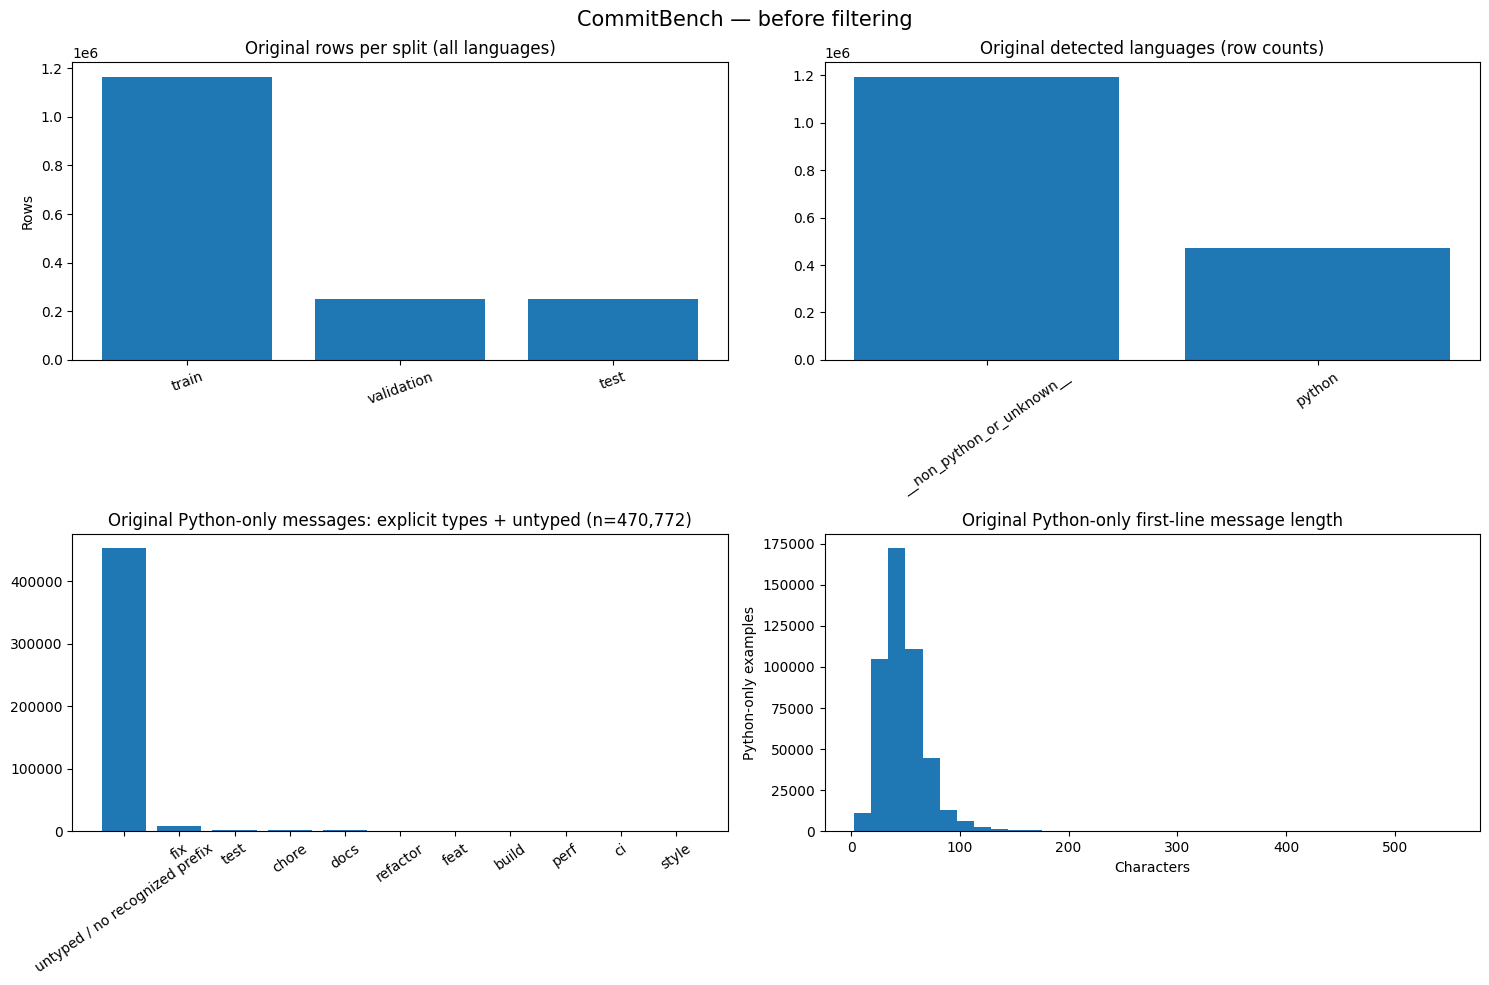

Original Python-only rows analyzed: 470,772
Saved original-data plots to: C:\Users\ASUSD\Desktop\Programing\seniorProject\OffHand\data\processed\plots\original_dataset_overview.png


In [7]:
# ---------------------------------------------------------------------------
# Overview plots — ORIGINAL dataset, with comparable Python-only label counts
# ---------------------------------------------------------------------------

def _safe_first_line(message):
    return (message or "").strip().splitlines()[0] if (message or "").strip() else ""


# Count only explicit, recognized commit-type prefixes. Do NOT infer labels here:
# the "after" chart uses this exact same rule, so the two distributions are comparable.
CANONICAL_TYPES = {
    "feat", "fix", "docs", "style", "refactor",
    "perf", "test", "build", "ci", "chore",
}
TYPE_ALIASES = {
    "feature": "feat", "features": "feat", "enhancement": "feat",
    "bugfix": "fix", "hotfix": "fix", "bug": "fix", "patch": "fix",
    "doc": "docs", "documentation": "docs",
    "tests": "test", "testing": "test",
    "performance": "perf", "optimization": "perf",
    "format": "style", "formatting": "style",
    "dependencies": "build", "deps": "build",
    "misc": "chore", "maintenance": "chore", "maint": "chore",
}
TYPE_ALIASES.update({t: t for t in CANONICAL_TYPES})
EXPLICIT_TYPE_RE = re.compile(
    r"^\s*(?P<type>[A-Za-z]+)(?:\([^)]*\))?!?\s*:\s*(?P<desc>\S.*)$"
)

def explicit_commit_type(message):
    """Canonical type only when the original first line has an explicit type prefix."""
    first = _safe_first_line(message)
    match = EXPLICIT_TYPE_RE.match(first)
    if not match:
        return None
    return TYPE_ALIASES.get(match.group("type").lower())


def _language_labels_for_plot(row):
    # One label per row. If paths are present, they take priority over metadata.
    by_path = _languages_from_diff_paths(row.get("diff") or "")
    langs = by_path if by_path is not None else _languages_from_metadata(row)
    return sorted(langs) if langs else ["unknown"]


original_split_sizes = {}
original_types = Counter()
original_message_lengths = []
original_languages = Counter()
original_python_rows = 0
original_python_untyped = 0

for split_name, split in ds.items():
    rows_to_analyze = split
    if LIMIT_PER_SPLIT is not None:
        rows_to_analyze = split.select(range(min(len(split), LIMIT_PER_SPLIT)))
    original_split_sizes[split_name] = len(rows_to_analyze)

    for row in tqdm(
        rows_to_analyze,
        desc=f"Analyze original {split_name}",
        total=len(rows_to_analyze),
    ):
        message = row.get("message") or ""
        first_line = _safe_first_line(message)

        for lang in _language_labels_for_plot(row):
            original_languages[lang] += 1

        # Compare the same population as the final output: Python-only rows.
        if is_target_language_example(row, TARGET_LANGUAGE):
            original_python_rows += 1
            ctype = explicit_commit_type(message)
            if ctype:
                original_types[ctype] += 1
            else:
                original_python_untyped += 1
            if message.strip():
                original_message_lengths.append(len(first_line))

original_types["untyped / no recognized prefix"] = original_python_untyped

PLOT_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes[0, 0].bar(list(original_split_sizes.keys()), list(original_split_sizes.values()))
axes[0, 0].set_title("Original rows per split (all languages)")
axes[0, 0].set_ylabel("Rows")
axes[0, 0].tick_params(axis="x", rotation=20)

top_languages = original_languages.most_common(12)
if top_languages:
    axes[0, 1].bar([x[0] for x in top_languages], [x[1] for x in top_languages])
    axes[0, 1].set_title("Original detected languages (row counts)")
    axes[0, 1].tick_params(axis="x", rotation=35)
else:
    axes[0, 1].set_title("Original detected languages (none found)")

top_types = original_types.most_common(12)
if top_types:
    axes[1, 0].bar([x[0] for x in top_types], [x[1] for x in top_types])
    axes[1, 0].set_title(
        f"Original Python-only messages: explicit types + untyped (n={original_python_rows:,})"
    )
    axes[1, 0].tick_params(axis="x", rotation=35)
else:
    axes[1, 0].set_title("Original Python-only message types (none found)")

if original_message_lengths:
    axes[1, 1].hist(original_message_lengths, bins=35)
axes[1, 1].set_title("Original Python-only first-line message length")
axes[1, 1].set_xlabel("Characters")
axes[1, 1].set_ylabel("Python-only examples")

fig.suptitle("CommitBench — before filtering", fontsize=15)
fig.tight_layout()
original_plot_path = PLOT_DIR / "original_dataset_overview.png"
fig.savefig(original_plot_path, dpi=FIGURE_DPI, bbox_inches="tight")
plt.show()
print(f"Original Python-only rows analyzed: {original_python_rows:,}")
print(f"Saved original-data plots to: {original_plot_path.resolve()}")


In [8]:
# ---------------------------------------------------------------------------
# Filter & write Python-only examples WITH recognized explicit commit types
# ---------------------------------------------------------------------------

MIN_DIFF_CHARS = 10
MIN_DESCRIPTION_CHARS = 3
USE_LOW_CONTENT_FILTER = True
DROP_MERGE_COMMITS = True
MERGE_RE = re.compile(r"^\s*merge (pull request|branch|remote-tracking)", re.I)


def build_example(
    diff: str,
    message: str,
    seen_hashes: set,
    type_counts: Counter,
    rejection_counts: Counter,
):
    """Return a typed row while preserving the original commit message."""

    def reject(reason):
        rejection_counts[reason] += 1
        return None

    message = (message or "").strip()
    if not message:
        return reject("empty_message")

    first_line = _safe_first_line(message)
    if DROP_MERGE_COMMITS and MERGE_RE.match(first_line):
        return reject("merge_commit")

    if USE_LOW_CONTENT_FILTER and message_is_low_content(message):
        return reject("low_content_message")

    cleaned_message = clean_training_message(message)
    if not cleaned_message:
        return reject("placeholder_cleaning_removed_message")

    cleaned_first_line = _safe_first_line(cleaned_message)
    commit_type = explicit_commit_type(cleaned_message)

    # Keep ONLY rows with a recognized explicit type. Never infer the type.
    if commit_type is None:
        return reject("missing_or_unrecognized_commit_type")

    match = EXPLICIT_TYPE_RE.match(cleaned_first_line)
    description = match.group("desc").strip() if match else ""
    if len(description) < MIN_DESCRIPTION_CHARS:
        return reject("description_too_short_after_cleaning")

    truncated = truncate_diff(diff or "")
    if truncated is None:
        return reject("no_usable_files_after_generated_file_filter")
    if len(truncated.strip()) < MIN_DIFF_CHARS:
        return reject("diff_too_short_after_filtering")

    digest = hashlib.sha256(
        (truncated + "\x00" + cleaned_message).encode("utf-8")
    ).hexdigest()[:16]
    if digest in seen_hashes:
        return reject("duplicate_diff_and_message")

    seen_hashes.add(digest)
    type_counts[commit_type] += 1

    # Keep diff + message for the existing generation notebook, and add
    # commit_type as a separate target for the future classification task.
    return {
        "diff": truncated,
        "message": cleaned_message,
        "commit_type": commit_type,
    }


OUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_SPLIT_NAMES = {
    "train": "train",
    "val": "validation",
    "validation": "validation",
    "test": "test",
}

for split_name in ds.keys():
    if split_name not in OUTPUT_SPLIT_NAMES:
        print(f"Skipping unexpected split '{split_name}'.")
        continue

    split = ds[split_name]
    if LIMIT_PER_SPLIT is not None:
        split = split.select(range(min(len(split), LIMIT_PER_SPLIT)))

    output_name = OUTPUT_SPLIT_NAMES[split_name]
    out_path = OUT_DIR / f"{output_name}.jsonl"

    seen_hashes = set()
    type_counts = Counter()
    rejection_counts = Counter()

    kept = 0
    seen = 0
    python_rows = 0
    language_removed = 0
    placeholder_cleaned = 0

    with out_path.open("w", encoding="utf-8") as f:
        for row in tqdm(
            split,
            desc=f"{split_name} -> {output_name}",
            total=len(split),
        ):
            seen += 1

            if not is_target_language_example(row, TARGET_LANGUAGE):
                language_removed += 1
                continue
            python_rows += 1

            diff = row.get("diff") or ""
            message = (row.get("message") or "").strip()

            if not diff.strip():
                rejection_counts["empty_diff"] += 1
                continue
            if not message:
                rejection_counts["empty_message"] += 1
                continue

            has_placeholder = bool(re.search(r"<(I|URL|EMAIL|HASH)>", message))

            example = build_example(
                diff=diff,
                message=message,
                seen_hashes=seen_hashes,
                type_counts=type_counts,
                rejection_counts=rejection_counts,
            )
            if example is None:
                continue

            if has_placeholder:
                placeholder_cleaned += 1

            f.write(json.dumps(example, ensure_ascii=False) + "\n")
            kept += 1

    rejected_after_language = sum(rejection_counts.values())
    accounted_for = kept + rejected_after_language

    print(
        f"\n{split_name}: kept {kept:,} typed examples from {seen:,} rows "
        f"({kept / max(seen, 1):.1%}) -> {out_path}"
    )
    print(f"  Python-only rows: {python_rows:,}")
    print(f"  Removed by language filter: {language_removed:,}")
    print(f"  Typed Python-only rows rejected by other checks: {rejected_after_language:,}")
    print(
        f"  Reconciliation: kept + rejected = {accounted_for:,} "
        f"(Python-only rows = {python_rows:,})"
    )
    if accounted_for != python_rows:
        print("  WARNING: counts do not reconcile; inspect the filtering loop.")

    print(f"  Placeholder-containing messages cleaned: {placeholder_cleaned:,}")
    print("  Rejection reasons (mutually exclusive):")
    if rejection_counts:
        for reason, count in rejection_counts.most_common():
            print(
                f"    {reason:<48} {count:>9,} "
                f"({count / max(python_rows, 1):.1%} of Python-only rows)"
            )
    else:
        print("    None")

    print("  Kept examples by commit_type:")
    for label, count in type_counts.most_common():
        print(f"    {label:<32} {count:>9,} ({count / max(kept, 1):.1%})")

print("\nFiltering complete. Expected outputs:")
for name in ("train.jsonl", "validation.jsonl", "test.jsonl"):
    print(f"  {OUT_DIR / name}")

train -> train: 100%|██████████| 1165213/1165213 [00:42<00:00, 27428.83it/s]



train: kept 12,338 typed examples from 1,165,213 rows (1.1%) -> C:\Users\ASUSD\Desktop\Programing\seniorProject\OffHand\data\processed\train.jsonl
  Python-only rows: 329,920
  Removed by language filter: 835,293
  Typed Python-only rows rejected by other checks: 317,582
  Reconciliation: kept + rejected = 329,920 (Python-only rows = 329,920)
  Placeholder-containing messages cleaned: 3,286
  Rejection reasons (mutually exclusive):
    missing_or_unrecognized_commit_type                317,023 (96.1% of Python-only rows)
    low_content_message                                    464 (0.1% of Python-only rows)
    merge_commit                                            41 (0.0% of Python-only rows)
    placeholder_cleaning_removed_message                    30 (0.0% of Python-only rows)
    no_usable_files_after_generated_file_filter             22 (0.0% of Python-only rows)
    duplicate_diff_and_message                               2 (0.0% of Python-only rows)
  Kept examples by com

validation -> validation: 100%|██████████| 249689/249689 [00:12<00:00, 19768.98it/s]



validation: kept 2,634 typed examples from 249,689 rows (1.1%) -> C:\Users\ASUSD\Desktop\Programing\seniorProject\OffHand\data\processed\validation.jsonl
  Python-only rows: 70,681
  Removed by language filter: 179,008
  Typed Python-only rows rejected by other checks: 68,047
  Reconciliation: kept + rejected = 70,681 (Python-only rows = 70,681)
  Placeholder-containing messages cleaned: 695
  Rejection reasons (mutually exclusive):
    missing_or_unrecognized_commit_type                 67,928 (96.1% of Python-only rows)
    low_content_message                                     96 (0.1% of Python-only rows)
    merge_commit                                             9 (0.0% of Python-only rows)
    placeholder_cleaning_removed_message                     9 (0.0% of Python-only rows)
    no_usable_files_after_generated_file_filter              4 (0.0% of Python-only rows)
    description_too_short_after_cleaning                     1 (0.0% of Python-only rows)
  Kept examples by co

test -> test: 100%|██████████| 249688/249688 [00:18<00:00, 13435.78it/s]


test: kept 2,727 typed examples from 249,688 rows (1.1%) -> C:\Users\ASUSD\Desktop\Programing\seniorProject\OffHand\data\processed\test.jsonl
  Python-only rows: 70,171
  Removed by language filter: 179,517
  Typed Python-only rows rejected by other checks: 67,444
  Reconciliation: kept + rejected = 70,171 (Python-only rows = 70,171)
  Placeholder-containing messages cleaned: 747
  Rejection reasons (mutually exclusive):
    missing_or_unrecognized_commit_type                 67,325 (95.9% of Python-only rows)
    low_content_message                                     99 (0.1% of Python-only rows)
    placeholder_cleaning_removed_message                    11 (0.0% of Python-only rows)
    merge_commit                                             7 (0.0% of Python-only rows)
    no_usable_files_after_generated_file_filter              2 (0.0% of Python-only rows)
  Kept examples by commit_type:
    fix                                  1,383 (50.7%)
    test                            

## How to interpret the before/after type charts

- **Before:** Python-only rows in the original source split, including an `untyped / no recognized prefix` category.
- **After:** only Python-only rows with a recognized, explicit commit type that survived the other filters.
- A type is accepted only when the first line explicitly starts with a recognized prefix such as `fix:` or `feat:` (optionally scoped, such as `fix(parser):`).
- Common aliases are normalized to canonical labels.
- The exported `message` keeps its original type prefix and wording (apart from placeholder cleaning).
- The exported `commit_type` is a separate canonical label for the future multi-task classification head.

No type is inferred from the code diff, and no `chore:` label is invented for untyped messages.

train: 12,338 typed examples
validation: 2,634 typed examples
test: 2,727 typed examples

Total typed examples checked: 17,699
Schema, non-empty fields, placeholder, explicit-type, and language checks passed.
Every exported row has a valid commit_type matching its message prefix.

Sample training examples:
  [1] TYPE:    test
      MESSAGE: test: automated_test: add missing user_script_test.
      DIFF:    diff --git a/test/automated_test.py b/test/automated_test.py
index <HASH>..<HASH> 100755
--- a/test/automated_test.py
+++ b/test/automated_test.py
@@ -55,6 +55,7 @@ from concurrenc...

  [2] TYPE:    fix
      MESSAGE: fix(openid): Mark tests as expected failures

Long term solution: phase out OpenID support. Current test relies on
Yahoo (dead now) and Hyves (should be long dead, if it isn't, it's
undead).

This fix silences the tests, until someone wants to find a new provider
or mock the discovery, but OpenID itself has moved on to the next shiny
version: OpenID Connect, so it is b

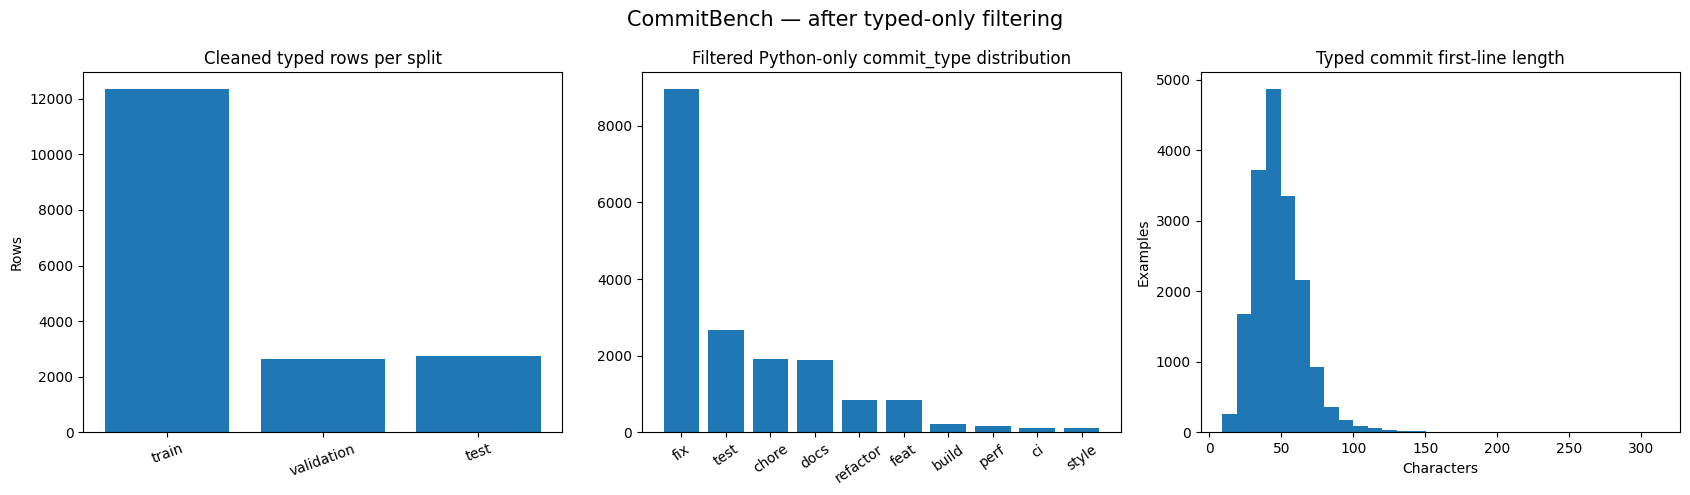

Saved typed-data plots to: C:\Users\ASUSD\Desktop\Programing\seniorProject\OffHand\data\processed\plots\cleaned_dataset_overview.png


: 

In [ ]:
# ---------------------------------------------------------------------------
# Sanity checks + overview plots — cleaned, typed-only dataset
# ---------------------------------------------------------------------------

available_output_files = {
    split_name: OUT_DIR / f"{split_name}.jsonl"
    for split_name in ("train", "validation", "test")
}
cleaned_split_sizes = {}
cleaned_types = Counter()
cleaned_message_lengths = []
total_checked = 0

for split_name, file_path in available_output_files.items():
    if not file_path.exists():
        print(f"Not present (source split may not exist): {file_path}")
        continue

    split_count = 0
    with file_path.open("r", encoding="utf-8") as f:
        for line_number, line in enumerate(f, start=1):
            if not line.strip():
                continue

            row = json.loads(line)
            expected_keys = {"diff", "message", "commit_type"}
            assert set(row.keys()) == expected_keys, (
                f"{file_path}:{line_number} expected keys {expected_keys}, "
                f"found {set(row.keys())}"
            )
            assert isinstance(row["diff"], str) and row["diff"].strip()
            assert isinstance(row["message"], str) and row["message"].strip()
            assert isinstance(row["commit_type"], str) and row["commit_type"].strip()

            for token in ("<I>", "<URL>", "<EMAIL>", "<HASH>"):
                assert token not in row["message"], (
                    f"{file_path}:{line_number} still contains placeholder {token}"
                )

            # Ensure the classification label matches the explicit prefix
            # retained in the generation target.
            extracted_type = explicit_commit_type(row["message"])
            assert extracted_type is not None, (
                f"{file_path}:{line_number} has no recognized explicit type prefix"
            )
            assert row["commit_type"] == extracted_type, (
                f"{file_path}:{line_number}: commit_type={row['commit_type']!r} "
                f"but message prefix resolves to {extracted_type!r}"
            )

            languages = _languages_from_diff_paths(row["diff"])
            if languages is not None:
                assert languages == {"python"}, (
                    f"{file_path}:{line_number} is not Python-only: {languages}"
                )

            cleaned_types[row["commit_type"]] += 1
            cleaned_message_lengths.append(len(_safe_first_line(row["message"])))
            split_count += 1
            total_checked += 1

    cleaned_split_sizes[split_name] = split_count
    print(f"{split_name}: {split_count:,} typed examples")

assert cleaned_split_sizes.get("train", 0) > 0, (
    "train.jsonl is missing or empty. Check the filters and source split names."
)
print(f"\nTotal typed examples checked: {total_checked:,}")
print("Schema, non-empty fields, placeholder, explicit-type, and language checks passed.")
print("Every exported row has a valid commit_type matching its message prefix.")


# Show a few training examples for a quick manual review.
train_path = OUT_DIR / "train.jsonl"
with train_path.open("r", encoding="utf-8") as f:
    print("\nSample training examples:")
    for i, line in enumerate(f):
        if i >= 3:
            break
        row = json.loads(line)
        print(f"  [{i + 1}] TYPE:    {row['commit_type']}")
        print(f"      MESSAGE: {row['message']}")
        print(f"      DIFF:    {row['diff'][:180]}...\n")

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
if cleaned_split_sizes:
    axes[0].bar(list(cleaned_split_sizes.keys()), list(cleaned_split_sizes.values()))
axes[0].set_title("Cleaned typed rows per split")
axes[0].set_ylabel("Rows")
axes[0].tick_params(axis="x", rotation=20)

top_cleaned_types = cleaned_types.most_common(12)
if top_cleaned_types:
    axes[1].bar([x[0] for x in top_cleaned_types], [x[1] for x in top_cleaned_types])
axes[1].set_title("Filtered Python-only commit_type distribution")
axes[1].tick_params(axis="x", rotation=35)

if cleaned_message_lengths:
    axes[2].hist(cleaned_message_lengths, bins=30)
axes[2].set_title("Typed commit first-line length")
axes[2].set_xlabel("Characters")
axes[2].set_ylabel("Examples")

fig.suptitle("CommitBench — after typed-only filtering", fontsize=15)
fig.tight_layout()
cleaned_plot_path = PLOT_DIR / "cleaned_dataset_overview.png"
fig.savefig(cleaned_plot_path, dpi=FIGURE_DPI, bbox_inches="tight")
plt.show()
print(f"Saved typed-data plots to: {cleaned_plot_path.resolve()}")